# Real Estate Housing Price Prediction: OLS vs. Ridge vs. Lasso

**Machine Learning & Data Science Internship Task 2**

Predict the **median house value** of California districts (1990 census) and compare three linear regression models:

| Model | Regularisation | Effect |
|---|---|---|
| Ordinary Least Squares (OLS) | none | baseline |
| Ridge | L2 penalty | shrinks correlated coefficients towards each other |
| Lasso | L1 penalty | can shrink coefficients to exactly zero (built-in feature selection) |

**Workflow**
1. Load the California Housing dataset (this version has missing values and a categorical column)
2. EDA: missing values, target distribution, geography, correlation heatmap
3. Feature engineering: ratio and interaction features
4. Multicollinearity analysis with the Variance Inflation Factor (VIF)
5. Preprocessing pipeline: median imputation, standardisation, one-hot encoding
6. OLS baseline, then Ridge and Lasso tuned over many `alpha` values with `GridSearchCV`
7. Compare RMSE, MAE and R², then plot predicted vs. actual values and residual distributions

## 1. Setup and imports

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

## 2. Load the dataset

We use the California Housing CSV popularised by *Hands-On Machine Learning* (Géron). Unlike
`sklearn.datasets.fetch_california_housing`, it keeps the raw count columns, includes real missing values
in `total_bedrooms`, and has a categorical `ocean_proximity` column, which lets us practise imputation and encoding.
A copy is stored in `../data/`; if it is missing, the notebook downloads it.

In [2]:
DATA_PATH = Path("../data/california_housing.csv")
DATA_URL = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

df = pd.read_csv(DATA_PATH) if DATA_PATH.exists() else pd.read_csv(DATA_URL)
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 20,640 rows x 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Exploratory data analysis

### 3.1 Types, missing values and summary statistics

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
missing = df.isnull().sum()
print("Missing values per column:")
print(missing[missing > 0])
print(f"\nShare of rows with a missing value: {df.isnull().any(axis=1).mean():.2%}")

Missing values per column:
total_bedrooms    207
dtype: int64

Share of rows with a missing value: 1.00%


In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
total_rooms,20640.0,2635.76,2181.62,2.00,1447.75,2127.00,3148.00,39320.00
total_bedrooms,20433.0,537.87,421.39,1.00,296.00,435.00,647.00,6445.00
population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
households,20640.0,499.54,382.33,1.00,280.00,409.00,605.00,6082.00
median_income,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
median_house_value,20640.0,206855.82,115395.62,14999.00,119600.00,179700.00,264725.00,500001.00


In [6]:
# The only categorical feature
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

### 3.2 Target distribution

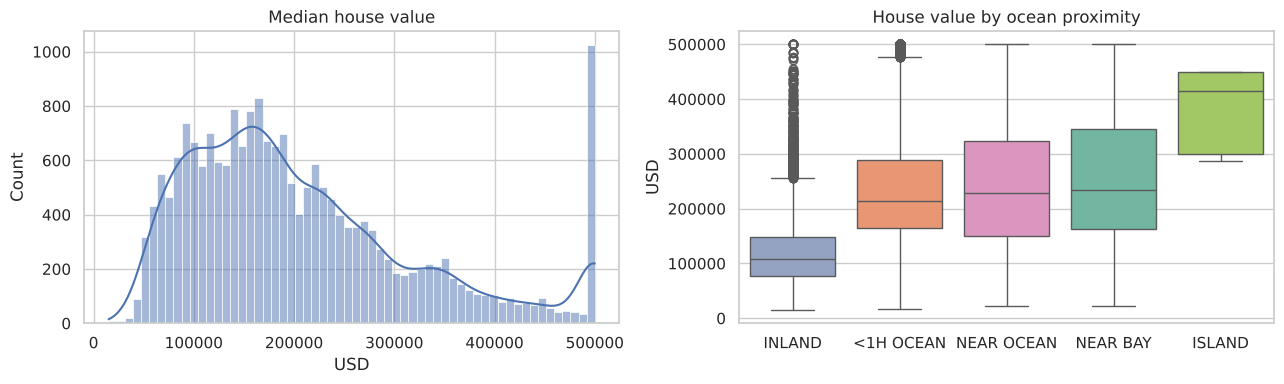

Districts at the 500,001 USD cap: 4.81%


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["median_house_value"], bins=60, kde=True, ax=axes[0], color="#4C72B0")
axes[0].set_title("Median house value")
axes[0].set_xlabel("USD")

sns.boxplot(data=df, x="ocean_proximity", y="median_house_value", hue="ocean_proximity",
            palette="Set2", legend=False, ax=axes[1],
            order=["INLAND", "<1H OCEAN", "NEAR OCEAN", "NEAR BAY", "ISLAND"])
axes[1].set_title("House value by ocean proximity")
axes[1].set_xlabel("")
axes[1].set_ylabel("USD")
plt.tight_layout()
plt.show()

capped = (df["median_house_value"] >= 500_000).mean()
print(f"Districts at the 500,001 USD cap: {capped:.2%}")

The target is right-skewed and **capped at 500,001 USD** (the spike at the right edge). A linear model will
under-predict those districts; we keep them so the evaluation reflects the real data. Inland districts are much
cheaper than coastal ones.

### 3.3 Geography

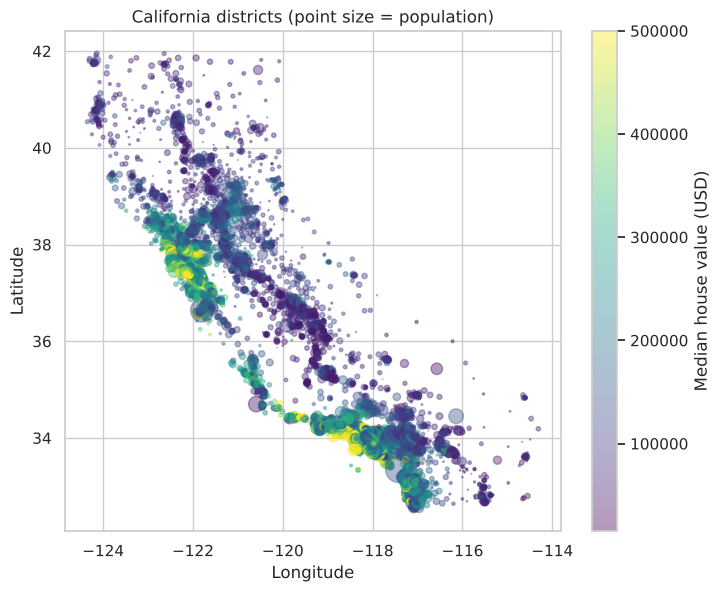

In [8]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sc = ax.scatter(df["longitude"], df["latitude"], c=df["median_house_value"], cmap="viridis",
                s=df["population"] / 100, alpha=0.4)
plt.colorbar(sc, ax=ax, label="Median house value (USD)")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("California districts (point size = population)")
plt.show()

Prices are highest along the coast, especially around the San Francisco Bay Area and Los Angeles.

### 3.4 Correlation heatmap

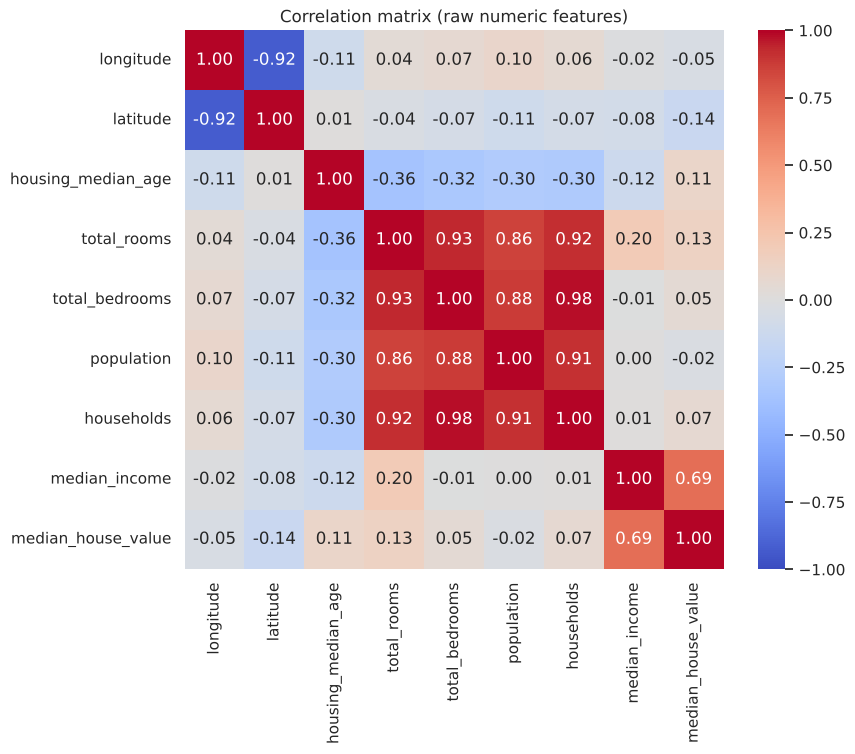

In [9]:
num_cols = df.select_dtypes("number").columns
plt.figure(figsize=(9, 7))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation matrix (raw numeric features)")
plt.show()

**Observations**
- `median_income` is by far the strongest single predictor of house value (r ≈ 0.69).
- `total_rooms`, `total_bedrooms`, `population` and `households` are almost perfectly correlated with each other
  (r > 0.85). They all measure district *size*, which is a classic **multicollinearity** problem for linear models.
- `longitude` and `latitude` are strongly negatively correlated because of California's diagonal shape.

## 4. Feature engineering

Raw counts mostly describe how big a district is, not how valuable its houses are. Per-household ratios are more
informative, and an interaction term lets a linear model capture effects that depend on two variables at once.

In [10]:
def add_features(data: pd.DataFrame) -> pd.DataFrame:
    """Return a copy of the data with engineered ratio and interaction features."""
    out = data.copy()
    # Ratio features: normalise counts by the number of households / rooms
    out["rooms_per_household"] = out["total_rooms"] / out["households"]
    out["bedrooms_per_room"] = out["total_bedrooms"] / out["total_rooms"]          # NaN where total_bedrooms is NaN
    out["population_per_household"] = out["population"] / out["households"]
    # Interaction features
    out["income_x_rooms"] = out["median_income"] * out["rooms_per_household"]       # wealth x house size
    out["income_x_age"] = out["median_income"] * out["housing_median_age"]          # wealth x neighbourhood age
    return out

df_fe = add_features(df)
new_cols = ["rooms_per_household", "bedrooms_per_room", "population_per_household", "income_x_rooms", "income_x_age"]
df_fe[new_cols + ["median_house_value"]].corr()["median_house_value"].drop("median_house_value").sort_values()

bedrooms_per_room          -0.255880
population_per_household   -0.023737
rooms_per_household         0.151948
income_x_rooms              0.555438
income_x_age                0.589142
Name: median_house_value, dtype: float64

`bedrooms_per_room` is clearly negatively correlated with value (more bedrooms per room means smaller, cheaper
homes), which neither raw count showed. The `income_x_age` interaction is also strongly related to the target.

## 5. Multicollinearity: Variance Inflation Factor

The VIF of a feature is `1 / (1 - R²)`, where R² comes from regressing that feature on all the other features.
A VIF above about 10 means the feature is largely redundant, which makes OLS coefficients unstable.

In [11]:
def compute_vif(data: pd.DataFrame) -> pd.Series:
    """Variance Inflation Factor for each column (rows with NaNs are dropped)."""
    X = data.dropna()
    X = (X - X.mean()) / X.std()
    vif = {}
    for col in X.columns:
        others = X.drop(columns=col)
        r2 = LinearRegression().fit(others, X[col]).score(others, X[col])
        vif[col] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(vif).sort_values(ascending=False)

all_numeric = [c for c in df_fe.select_dtypes("number").columns if c != "median_house_value"]
vif_before = compute_vif(df_fe[all_numeric])
vif_before.round(1).to_frame("VIF (all numeric features)")

,VIF (all numeric features)
total_bedrooms,49.9
households,44.6
median_income,20.2
total_rooms,19.3
income_x_rooms,18.3
latitude,9.6
income_x_age,9.3
longitude,9.2
population,6.9
rooms_per_household,5.5


The raw count columns have very high VIFs, and so do the interaction terms built from them. We drop the four raw
count columns (`total_rooms`, `total_bedrooms`, `population`, `households`); their information is kept in the
ratio features. `income_x_rooms` is also dropped because it largely duplicates `median_income`. Ridge and Lasso
would cope with the collinearity anyway, but removing obvious redundancy gives OLS a fair chance and makes all the
coefficients easier to read.

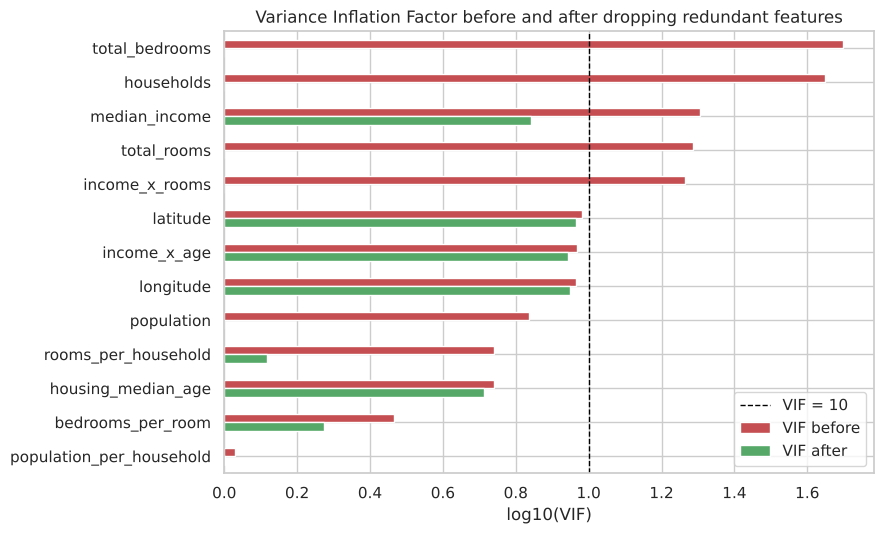

Remaining numeric features: ['longitude', 'latitude', 'housing_median_age', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_age']
Max VIF after: 9.2


In [12]:
DROP_COLS = ["total_rooms", "total_bedrooms", "population", "households", "income_x_rooms"]
numeric_features = [c for c in all_numeric if c not in DROP_COLS]
categorical_features = ["ocean_proximity"]

vif_after = compute_vif(df_fe[numeric_features])

vif_compare = pd.concat([vif_before.rename("VIF before"), vif_after.rename("VIF after")], axis=1)
vif_compare = vif_compare.sort_values("VIF before", ascending=False)

ax = np.log10(vif_compare.replace(np.inf, 1e4)).plot(kind="barh", figsize=(9, 5.5), color=["#C44E52", "#55A868"])
ax.axvline(1, color="black", ls="--", lw=1, label="VIF = 10")
ax.set_xlabel("log10(VIF)")
ax.set_title("Variance Inflation Factor before and after dropping redundant features")
ax.invert_yaxis()
ax.legend()
plt.tight_layout()
plt.show()

print("Remaining numeric features:", numeric_features)
print("Max VIF after:", round(vif_after.max(), 1))

The remaining moderate VIFs come from `longitude`/`latitude` (geography) and from `income_x_age`, which shares
information with `median_income` and `housing_median_age`. That level of overlap is acceptable, and it is
exactly the situation Ridge regularisation is designed for.

## 6. Train/test split and preprocessing pipeline

- **80/20 split** with a fixed random seed.
- Imputation and scaling live **inside a scikit-learn `Pipeline`**, so their statistics are learned from the
  training data only (no leakage), including inside every cross-validation fold.
  - Numeric: `SimpleImputer(strategy="median")` (median is robust to skew) then `StandardScaler`.
  - Categorical: `OneHotEncoder(drop="first")`: one binary column per `ocean_proximity` value, minus the first
    category (`<1H OCEAN`), which becomes the baseline. Dropping it avoids perfect multicollinearity with the intercept.

In [13]:
X = df_fe[numeric_features + categorical_features]
y = df_fe["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(f"Training set: {len(X_train):,} rows | Test set: {len(X_test):,} rows")
print(f"Missing values in training features: {X_train.isnull().sum().sum()} (handled by the imputer)")

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numeric_features),
    # drop="first" removes one redundant dummy column (the "dummy variable trap"), which would otherwise be
    # perfectly collinear with the intercept
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), categorical_features),
])

def make_pipeline(model):
    """Preprocessing followed by a regression model."""
    return Pipeline([("prep", preprocessor), ("model", model)])

Training set: 16,512 rows | Test set: 4,128 rows
Missing values in training features: 0 (handled by the imputer)


## 7. Model training

### 7.1 OLS baseline

In [14]:
ols = make_pipeline(LinearRegression())
ols.fit(X_train, y_train)
print("OLS fitted.")

OLS fitted.


### 7.2 Ridge and Lasso with `GridSearchCV`

We search each model over 30 `alpha` values on a log scale using 5-fold cross-validation, scoring by RMSE
(scikit-learn maximises scores, so RMSE is reported as a negative number during the search).

In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_search = GridSearchCV(
    make_pipeline(Ridge()),
    param_grid={"model__alpha": np.logspace(-3, 3, 30)},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, return_train_score=True,
)
ridge_search.fit(X_train, y_train)

lasso_search = GridSearchCV(
    make_pipeline(Lasso(max_iter=50_000)),
    param_grid={"model__alpha": np.logspace(-2, 4, 30)},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, return_train_score=True,
)
lasso_search.fit(X_train, y_train)

for name, search in [("Ridge", ridge_search), ("Lasso", lasso_search)]:
    print(f"{name}: best alpha = {search.best_params_['model__alpha']:.4g}, "
          f"CV RMSE = {-search.best_score_:,.0f} USD")

Ridge: best alpha = 1.269, CV RMSE = 70,471 USD
Lasso: best alpha = 7.88, CV RMSE = 70,477 USD


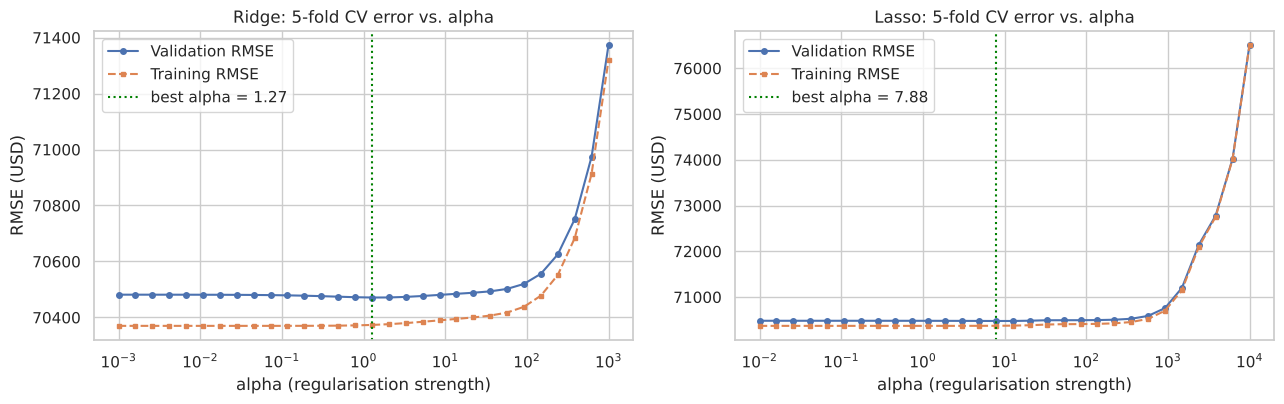

In [16]:
# How does cross-validated RMSE change with alpha?
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, (name, search) in zip(axes, [("Ridge", ridge_search), ("Lasso", lasso_search)]):
    res = pd.DataFrame(search.cv_results_)
    alphas = res["param_model__alpha"].astype(float)
    ax.plot(alphas, -res["mean_test_score"], "o-", label="Validation RMSE", color="#4C72B0", ms=4)
    ax.plot(alphas, -res["mean_train_score"], "s--", label="Training RMSE", color="#DD8452", ms=3)
    best_alpha = search.best_params_["model__alpha"]
    ax.axvline(best_alpha, color="green", ls=":", label=f"best alpha = {best_alpha:.3g}")
    ax.set_xscale("log")
    ax.set_xlabel("alpha (regularisation strength)")
    ax.set_ylabel("RMSE (USD)")
    ax.set_title(f"{name}: 5-fold CV error vs. alpha")
    ax.legend()
plt.tight_layout()
plt.show()

For small `alpha`, Ridge and Lasso behave like OLS. As `alpha` grows the coefficients are shrunk harder, and
eventually the model underfits and the error rises sharply. The best `alpha` sits on the flat part of the curve,
which tells us that this feature set does not overfit much: there are 20k rows and only about 15 features.

## 8. Evaluation: RMSE, MAE and R²

In [17]:
models = {
    "OLS (LinearRegression)": ols,
    "Ridge (L2)": ridge_search.best_estimator_,
    "Lasso (L1)": lasso_search.best_estimator_,
}

def regression_metrics(y_true, y_pred):
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "MAE": mean_absolute_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

rows, test_preds = [], {}
for name, model in models.items():
    test_preds[name] = model.predict(X_test)
    train_m = regression_metrics(y_train, model.predict(X_train))
    test_m = regression_metrics(y_test, test_preds[name])
    rows.append({"Model": name,
                 "Train RMSE": train_m["RMSE"], "Test RMSE": test_m["RMSE"],
                 "Train MAE": train_m["MAE"], "Test MAE": test_m["MAE"],
                 "Train R2": train_m["R2"], "Test R2": test_m["R2"]})

results = pd.DataFrame(rows).set_index("Model")
results.style.format({c: "{:,.0f}" for c in results.columns if "R2" not in c} | {"Train R2": "{:.4f}", "Test R2": "{:.4f}"})

,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2
Model,,,,,,
OLS (LinearRegression),"70,383","71,931","50,941","51,221",0.6294,0.6052
Ridge (L2),"70,385","71,942","50,943","51,230",0.6294,0.6050
Lasso (L1),"70,385","71,941","50,942","51,230",0.6294,0.6050


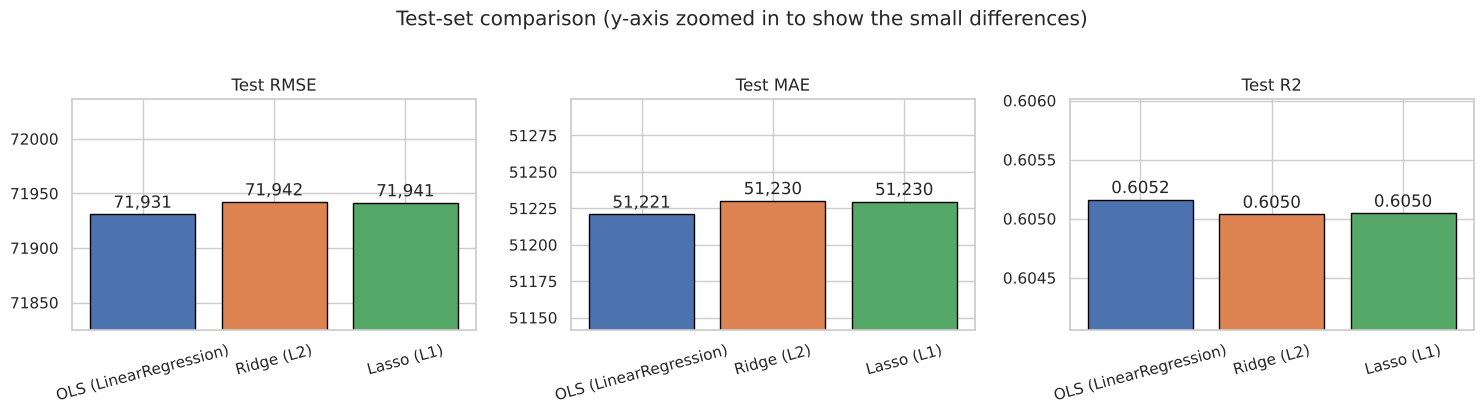

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette = ["#4C72B0", "#DD8452", "#55A868"]
for ax, metric in zip(axes, ["Test RMSE", "Test MAE", "Test R2"]):
    vals = results[metric]
    bars = ax.bar(vals.index, vals.values, color=palette, edgecolor="black")
    ax.bar_label(bars, fmt="%.4f" if "R2" in metric else "{:,.0f}", padding=2)
    ax.set_title(metric)
    ax.tick_params(axis="x", rotation=15)
    lo, hi = vals.min(), vals.max()
    ax.set_ylim(lo - (hi - lo) * 3 - 1e-3 * hi, hi + (hi - lo) * 2 + 1e-3 * hi)
plt.suptitle("Test-set comparison (y-axis zoomed in to show the small differences)", y=1.03)
plt.tight_layout()
plt.show()

## 9. Coefficients: how L1 and L2 change the model

All inputs are standardised, so coefficient size is comparable across numeric features (USD change in the
prediction per one standard deviation of the feature).

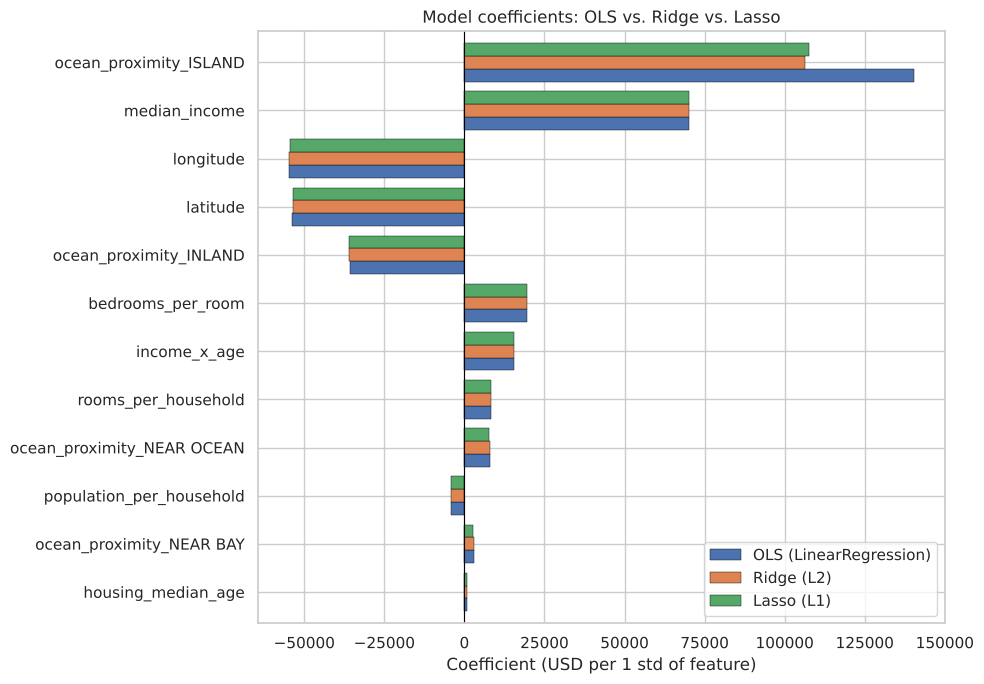

Features Lasso set exactly to zero: none


In [19]:
feature_out = ols.named_steps["prep"].get_feature_names_out()
feature_out = [f.split("__", 1)[1] for f in feature_out]

coefs = pd.DataFrame({name: m.named_steps["model"].coef_ for name, m in models.items()}, index=feature_out)
coefs = coefs.reindex(coefs["OLS (LinearRegression)"].abs().sort_values().index)

ax = coefs.plot(kind="barh", figsize=(10, 7), color=palette, width=0.8, edgecolor="black", linewidth=0.3)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Coefficient (USD per 1 std of feature)")
ax.set_title("Model coefficients: OLS vs. Ridge vs. Lasso")
plt.tight_layout()
plt.show()

zeroed = coefs.index[coefs["Lasso (L1)"].abs() < 1e-8].tolist()
print("Features Lasso set exactly to zero:", zeroed if zeroed else "none")

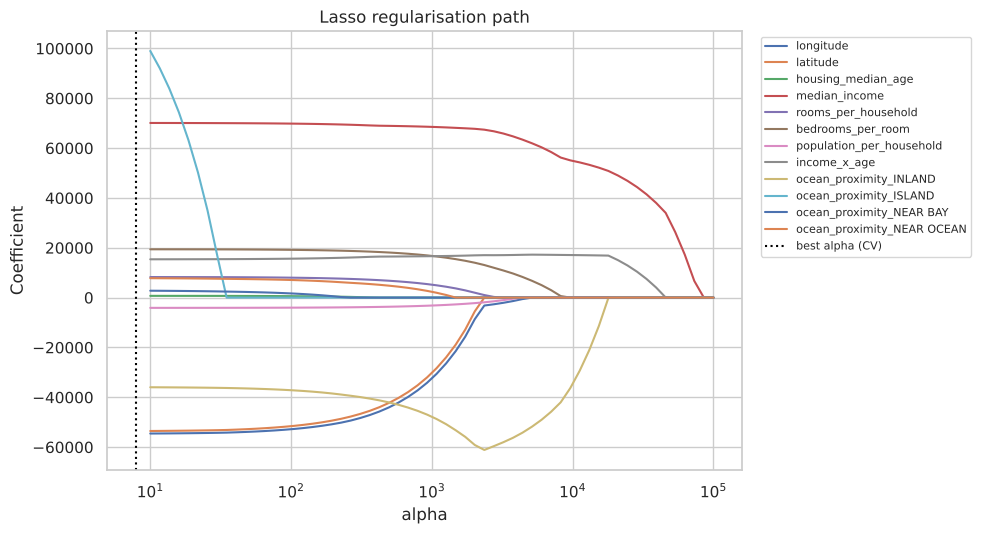

In [20]:
# Lasso regularisation path: watch coefficients shrink to zero as alpha increases
prep_train = preprocessor.fit_transform(X_train)
alphas = np.logspace(1, 5, 60)
path = np.array([Lasso(alpha=a, max_iter=50_000).fit(prep_train, y_train).coef_ for a in alphas])

plt.figure(figsize=(10, 5.5))
for j, fname in enumerate(feature_out):
    plt.plot(alphas, path[:, j], label=fname, lw=1.5)
plt.axvline(lasso_search.best_params_["model__alpha"], color="black", ls=":", label="best alpha (CV)")
plt.xscale("log")
plt.xlabel("alpha")
plt.ylabel("Coefficient")
plt.title("Lasso regularisation path")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

Reading the path from left to right (weak to strong penalty):
- The `ocean_proximity_ISLAND` coefficient collapses first. Only 5 districts are on an island, so Lasso quickly
  decides that this large but poorly supported coefficient is not worth its penalty.
- `longitude`, `latitude` and the `NEAR BAY` / `NEAR OCEAN` dummies drop out at around `alpha ≈ 2,000`.
- `ocean_proximity_INLAND`, `income_x_age` and above all `median_income` survive the strongest penalties, which
  confirms that income and being inland are the most important signals in this dataset.

## 10. Predicted vs. actual values

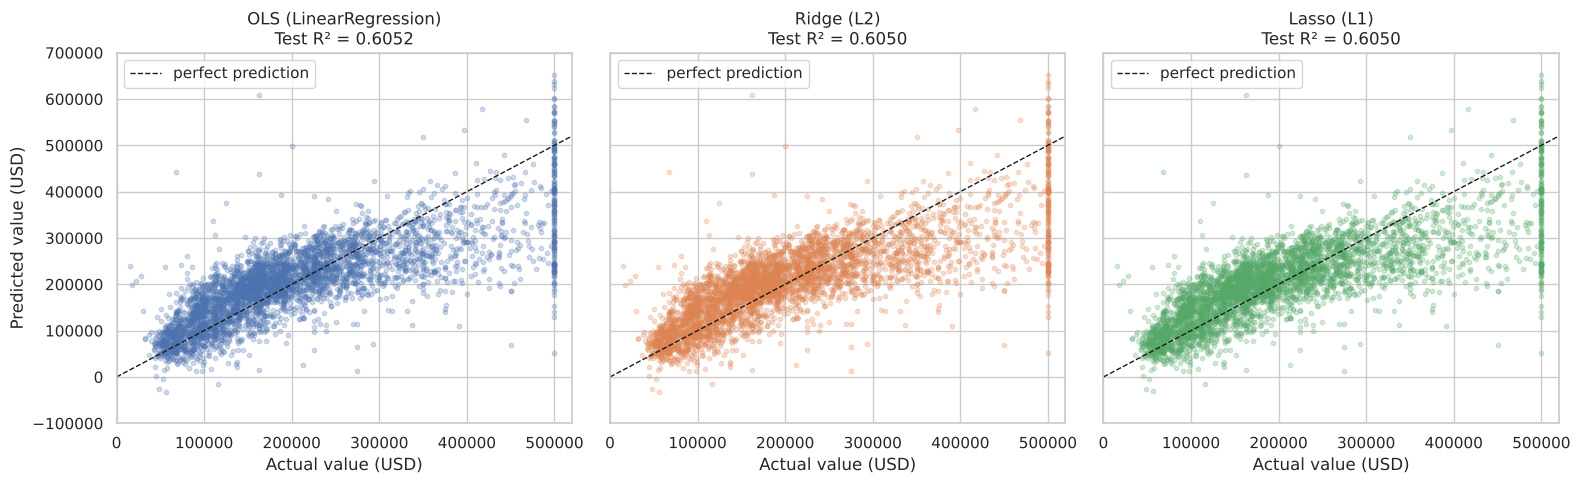

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lims = [0, 520_000]
for ax, (name, y_pred), color in zip(axes, test_preds.items(), palette):
    ax.scatter(y_test, y_pred, alpha=0.25, s=10, color=color)
    ax.plot(lims, lims, "k--", lw=1, label="perfect prediction")
    r2 = r2_score(y_test, y_pred)
    ax.set_title(f"{name}\nTest R² = {r2:.4f}")
    ax.set_xlabel("Actual value (USD)")
    ax.set_xlim(lims)
    ax.set_ylim(-100_000, 700_000)
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted value (USD)")
plt.tight_layout()
plt.show()

Points follow the diagonal reasonably well, but there is a visible vertical stripe at 500,001 USD: those districts
are capped, so their real value is higher and the models cannot know how much higher.

## 11. Residual analysis

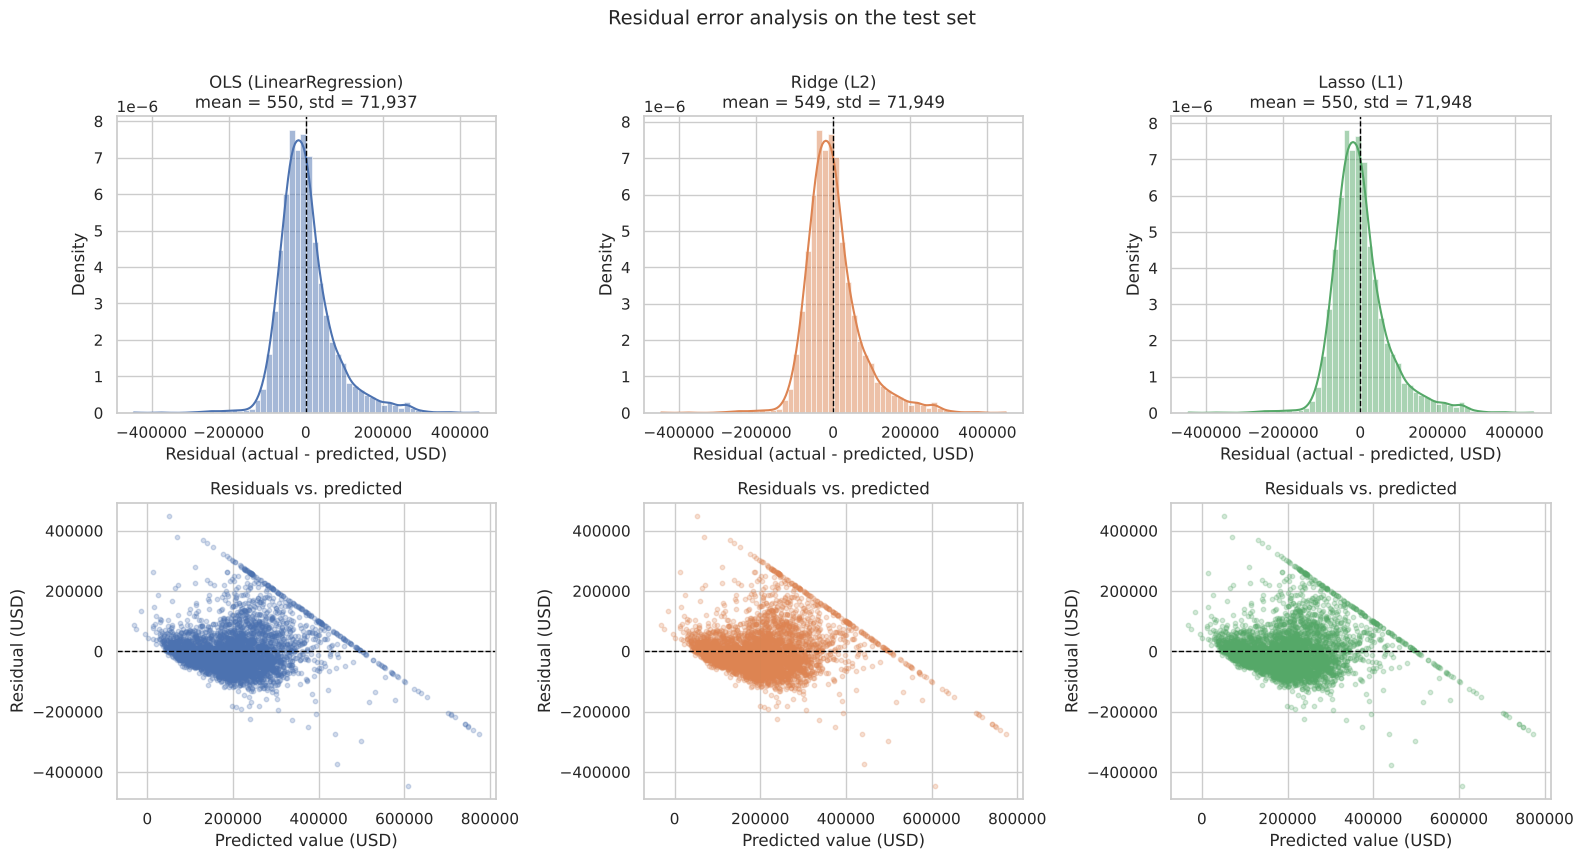

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
for i, ((name, y_pred), color) in enumerate(zip(test_preds.items(), palette)):
    residuals = y_test - y_pred

    # Top row: residual distribution curve
    sns.histplot(residuals, bins=60, kde=True, ax=axes[0, i], color=color, stat="density")
    axes[0, i].axvline(0, color="black", ls="--", lw=1)
    axes[0, i].set_title(f"{name}\nmean = {residuals.mean():,.0f}, std = {residuals.std():,.0f}")
    axes[0, i].set_xlabel("Residual (actual - predicted, USD)")

    # Bottom row: residuals vs. predicted values
    axes[1, i].scatter(y_pred, residuals, alpha=0.25, s=10, color=color)
    axes[1, i].axhline(0, color="black", ls="--", lw=1)
    axes[1, i].set_xlabel("Predicted value (USD)")
    axes[1, i].set_ylabel("Residual (USD)")
    axes[1, i].set_title("Residuals vs. predicted")
plt.suptitle("Residual error analysis on the test set", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

**Reading the residual plots**
- The residuals are centred near zero and roughly bell-shaped, with a longer right tail: the models
  under-predict some expensive districts.
- In the residuals vs. predicted plots, the diagonal band of points running down to the right is the 500,001 USD
  cap. The spread also widens as predictions grow (**heteroscedasticity**), a sign that a log-transformed target or
  a non-linear model would fit better.
- The three models produce almost identical residual patterns.

## 12. Conclusion

In [23]:
print(results[["Test RMSE", "Test MAE", "Test R2"]].round(4).to_string())
best = results["Test RMSE"].idxmin()
print(f"\nLowest test RMSE: {best}")
print(f"Ridge best alpha: {ridge_search.best_params_['model__alpha']:.4g}")
print(f"Lasso best alpha: {lasso_search.best_params_['model__alpha']:.4g}")

                         Test RMSE    Test MAE  Test R2
Model                                                  
OLS (LinearRegression)  71930.6813  51220.7667   0.6052
Ridge (L2)              71941.9705  51230.1001   0.6050
Lasso (L1)              71941.1366  51229.5019   0.6050

Lowest test RMSE: OLS (LinearRegression)
Ridge best alpha: 1.269
Lasso best alpha: 7.88


**Summary**
- After imputing `total_bedrooms`, one-hot encoding `ocean_proximity`, engineering ratio and interaction features
  and removing the most collinear raw counts, all three linear models explain about **60% of the variance** in house
  values on unseen data (test R² ≈ 0.605, RMSE ≈ 71,900 USD, MAE ≈ 51,200 USD).
- **Ridge and Lasso perform almost identically to OLS** (test RMSEs within about 15 USD of each other). With about 16k training rows and a compact, de-correlated
  feature set, plain OLS is not overfitting, so cross-validation picks small `alpha` values and regularisation brings
  only marginal gains. Regularisation matters much more when there are many correlated or noisy features.
- The coefficient plots and the Lasso path show that **median income**, **location** (inland vs. coastal, longitude,
  latitude) and **bedrooms per room** drive the predictions.
- The residual analysis exposes the limits of a linear model on this data: the 500k cap and the growing error
  spread at higher prices.

**Possible next steps**
- Predict `log(median_house_value)` to reduce heteroscedasticity, or drop the capped districts.
- Add polynomial features (`PolynomialFeatures`) and let Ridge/Lasso control the larger feature space.
- Try non-linear models such as Random Forest or Gradient Boosting, which usually cut RMSE substantially on this dataset.